# Ocean layers: heat exchange and conservation

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/32-ocean.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/32-ocean.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `f449d2cf86ac9192c33a1979565a350ba4aa3f09424b36fbfdc36dc0b5faab44`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Ocean layers: heat exchange and conservation

**Lesson 32 · Original synthetic data · Independent educational project**

## Objectives

Couple two heat reservoirs; account for surface forcing; test energy conservation.

[Previous](31-sea-ice.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/32-ocean.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=32-ocean.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

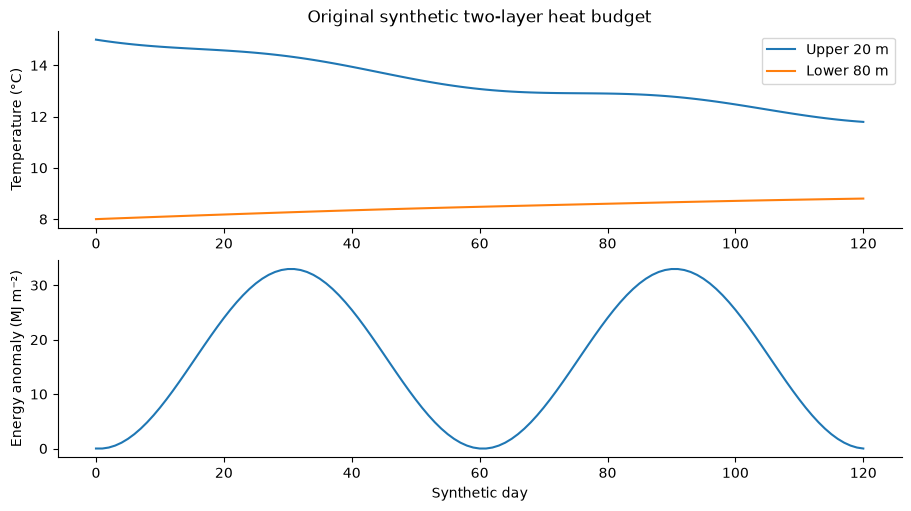

Largest daily energy-budget residual: 3.06e-07 J m⁻²


In [2]:
day = np.arange(120)
dt = 86400.  # seconds per daily interval
heat_capacity = 4e6  # chosen volumetric heat capacity, J m⁻³ K⁻¹
upper_capacity, lower_capacity = heat_capacity*20, heat_capacity*80
exchange = 5.  # chosen exchange coefficient, W m⁻² K⁻¹
surface_flux = 20*np.sin(2*np.pi*day/60)  # original forcing, W m⁻²
upper, lower = np.zeros(len(day)+1), np.zeros(len(day)+1)
upper[0], lower[0] = 15., 8.
for i in range(len(day)):
    transfer = exchange*(upper[i]-lower[i])
    upper[i+1] = upper[i] + dt*(surface_flux[i]-transfer)/upper_capacity
    lower[i+1] = lower[i] + dt*transfer/lower_capacity
change = upper_capacity*np.diff(upper) + lower_capacity*np.diff(lower)
assert np.allclose(change, dt*surface_flux, rtol=1e-9, atol=1e-6)
assert dt*exchange*(1/upper_capacity+1/lower_capacity) < 1
energy_anomaly = upper_capacity*(upper-upper[0]) + lower_capacity*(lower-lower[0])
assert np.allclose(energy_anomaly, np.r_[0, np.cumsum(dt*surface_flux)], atol=2e-6)
fig, axes = plt.subplots(2, 1, figsize=(9, 5), constrained_layout=True)
axes[0].plot(np.arange(len(upper)), upper, label="Upper 20 m")
axes[0].plot(np.arange(len(lower)), lower, label="Lower 80 m")
axes[0].set(ylabel="Temperature (°C)", title="Original synthetic two-layer heat budget")
axes[0].legend()
axes[1].plot(np.arange(len(energy_anomaly)), energy_anomaly/1e6)
axes[1].set(xlabel="Synthetic day", ylabel="Energy anomaly (MJ m⁻²)")
plt.show()
print(f"Largest daily energy-budget residual: {np.max(np.abs(change-dt*surface_flux)):.2e} J m⁻²")

## Exercise

Double the upper-layer depth and compare response amplitude. Change the exchange coefficient while checking both energy conservation and time-step stability.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

ECMWF's ocean ML component targets evolving ocean fields through depth, including temperature, salinity, currents and sea-surface-height anomalies. This original two-reservoir model illustrates heat exchange only. It has no circulation, salinity, sea-level dynamics, assimilation or trained ML model. Chosen parameters are teaching assumptions; the curves cannot be interpreted as ocean projections.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://destine.ecmwf.int/ml-earth-system-components/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).